# multiwell-mea-analysis example workflow

Minimal walkthrough using the toolbox's core building blocks directly:

After exporing data from MCS systems, we need to combine the recording and perform basic quality control. 
In some cases the burst detection of MCS does not work too well and reexporting all files with different MSC paramters can take a long time. This toolbox allows to redefine the burst detection and bursts and network detect bursts again for the whole batch of recordings. 

In this notebook you will learn how to:
1. Process one recording file into a per-well features `DataFrame`.
2. QC the detected bursts well-by-well with the interactive widget.
3. Plot a raster for one well.

This skips the project-specific batch pipeline (filename parsing, layout
files, `ProcessPoolExecutor` over many files) since this example only has
one recording to work with.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from multiwell_mea_analysis.MEA_features import read_ephys, get_features, gid_to_numbers, feature_names
from multiwell_mea_analysis.burst_qc_widget import create_burst_qc_widget

## 1) Process the file into a features DataFrame

`read_ephys` loads the spikes/bursts/networkbursts CSVs for the file once;
`get_features` then computes the per-well feature set for each well.

In [2]:
file_path = os.path.join('data', 'CACNA1E_Bioni37A_29_3_baseline_20250305_20250403_spikes.csv')

spikes, bursts, netbursts = read_ephys(file_path)
wells = sorted(spikes['Well Label'].unique())

rows = [
    [file_path, well, *get_features(well, spikes, bursts, netbursts)]
    for well in wells
]
df = pd.DataFrame(rows, columns=['file_path', 'well', *feature_names])
df.head()

/Users/ovinogradov/Documents/Projects/MEA-analysis-base/multiwell_mea_analysis/MEA_features.py:120: RuntimeWarning: Mean of empty slice
  np.nanmean(mibis),
/Users/ovinogradov/Documents/Projects/MEA-analysis-base/multiwell_mea_analysis/MEA_features.py:121: RuntimeWarning: Mean of empty slice
  np.nanmean(cv_ibis),
/Users/ovinogradov/Documents/Projects/MEA-analysis-base/multiwell_mea_analysis/MEA_features.py:122: RuntimeWarning: Mean of empty slice
  np.nanmean(burst_rates),
/Users/ovinogradov/Documents/Projects/MEA-analysis-base/multiwell_mea_analysis/MEA_features.py:123: RuntimeWarning: Mean of empty slice
  np.nanmean(mbd),
/Users/ovinogradov/Documents/Projects/MEA-analysis-base/multiwell_mea_analysis/MEA_features.py:124: RuntimeWarning: Mean of empty slice
  np.nanmean(cv_bds),
/Users/ovinogradov/Documents/Projects/MEA-analysis-base/multiwell_mea_analysis/MEA_features.py:125: RuntimeWarning: Mean of empty slice
  np.nanmean(avg_rate_in_burst)
/Users/ovinogradov/miniconda3/envs/kcnh1

,file_path,well,ISI [s],CV_ISI,FR [Hz],IBI (MCS) [s],CV_IBI (MCS),Burst_Rate (MCS) [Hz],BD (MCS) [s],CV_BD (MCS),...,NBD (MCS) [s],CV_NBD (MCS),NIBI (custom) [s],CV_NIBI (custom),NBD (custom) [s],CV_NBD (custom),In-NB_Rate (MCS) [Hz],Random_Spikes (MCS) [%],Total_Burst_Time (MCS),smbr (MCS)
0,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A1,0.331929,3.934419,4.980823,12.757490,1.023169,0.081542,0.401073,0.701178,...,1.123046,0.251523,24.709818,0.150473,1.698333,0.058586,915.363853,24.172943,0.048682,0.083333
1,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A2,0.184327,4.596032,6.083098,11.305736,0.835156,0.088612,0.394648,0.588980,...,1.030269,0.101760,17.681800,0.213338,1.350062,0.114626,1048.639648,21.443902,0.054948,0.000000
2,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A3,0.288130,4.185486,4.351575,11.972195,0.823609,0.080842,0.323009,0.527778,...,0.891220,0.101599,17.526929,0.288268,1.183400,0.121635,940.211474,20.148110,0.044566,0.000000
3,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A4,0.124922,3.865405,8.505921,10.576903,0.849551,0.093945,0.531548,0.640930,...,1.087458,0.293082,17.014600,0.151142,1.685500,0.072449,1162.932410,21.484822,0.065287,0.117647
4,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A5,1.290092,4.692344,6.676835,9.715796,0.878261,0.105176,0.438610,0.635979,...,1.170608,0.123559,15.329588,0.206099,1.467889,0.078916,947.338043,17.464941,0.070253,0.000000


## 2) QC bursts with the interactive widget

The widget writes `accepted` and `burst parameters` back into `df` in
place as you step through wells and accept/reject them.

In [4]:
qc_widget = create_burst_qc_widget(df)
qc_widget

In [5]:
# After QC, keep only accepted wells
df_accepted = df[df['accepted']]
df_accepted.head()

,file_path,well,ISI [s],CV_ISI,FR [Hz],IBI (MCS) [s],CV_IBI (MCS),Burst_Rate (MCS) [Hz],BD (MCS) [s],CV_BD (MCS),...,NIBI (custom) [s],CV_NIBI (custom),NBD (custom) [s],CV_NBD (custom),In-NB_Rate (MCS) [Hz],Random_Spikes (MCS) [%],Total_Burst_Time (MCS),smbr (MCS),accepted,burst parameters
0,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A1,0.331929,3.934419,4.980823,12.757490,1.023169,0.081542,0.401073,0.701178,...,24.709818,0.150473,1.698333,0.058586,915.363853,24.172943,0.048682,0.083333,True,
1,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A2,0.184327,4.596032,6.083098,11.305736,0.835156,0.088612,0.394648,0.588980,...,17.681800,0.213338,1.350062,0.114626,1048.639648,21.443902,0.054948,0.000000,True,
2,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A3,0.288130,4.185486,4.351575,11.972195,0.823609,0.080842,0.323009,0.527778,...,17.526929,0.288268,1.183400,0.121635,940.211474,20.148110,0.044566,0.000000,True,
3,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A4,0.124922,3.865405,8.505921,10.576903,0.849551,0.093945,0.531548,0.640930,...,17.014600,0.151142,1.685500,0.072449,1162.932410,21.484822,0.065287,0.117647,True,
4,data/CACNA1E_Bioni37A_29_3_baseline_20250305_2...,A5,1.290092,4.692344,6.676835,9.715796,0.878261,0.105176,0.438610,0.635979,...,15.329588,0.206099,1.467889,0.078916,947.338043,17.464941,0.070253,0.000000,True,


## 3) Save the features table

Hand the QC'd table off to other notebooks (e.g.
`example_condition_registration.ipynb`) instead of each one
recomputing features from the raw recording.

In [6]:
output_path = os.path.join('results', 'features_table.csv')
os.makedirs('results', exist_ok=True)
df_accepted.to_csv(output_path, index=False)
output_path

'results/features_table.csv'

## 4) Raster plot of one well

Spike raster on top, population firing rate (Hz per channel, 50 ms bins)
below it on a shared time axis.

/var/folders/x4/6b9j72f910d1lpcfkv5qb37w0000gn/T/ipykernel_6724/700845887.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


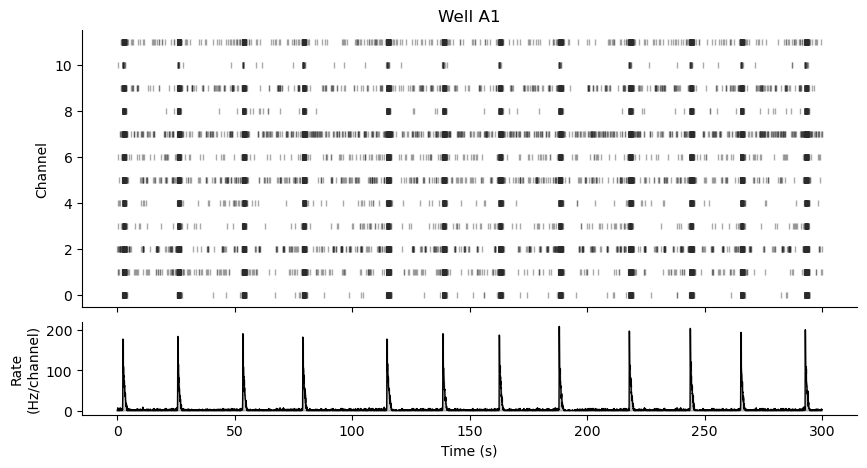

In [7]:
# Use the first well that survived QC (step 2); falls back to the
# first well overall if nothing has been reviewed/accepted yet.
accepted_wells = df_accepted if len(df_accepted) else df
well = accepted_wells['well'].iloc[0]

spikes_well = spikes[spikes['Well Label'] == well]

st = spikes_well['Timestamp [µs]'].to_numpy() * 1e-6
channel_ids = spikes_well['Channel ID'].to_numpy()
gid = gid_to_numbers(channel_ids)
n_channels = len(np.unique(channel_ids))

bin_width = 0.05  # seconds
bins = np.arange(0, st.max() + bin_width, bin_width)
counts, bin_edges = np.histogram(st, bins)
rate_hz = counts / bin_width / n_channels  # per-channel firing rate

fig, (ax_raster, ax_rate) = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True,
    gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.08},
)

ax_raster.plot(st, gid, '|', color='#2b2b2b', alpha=0.4, markersize=4, markeredgewidth=1)
ax_raster.set_ylabel('Channel')
ax_raster.set_title(f'Well {well}', fontsize=12)
ax_raster.spines[['top', 'right']].set_visible(False)

ax_rate.plot(bin_edges[1:], rate_hz, color='k', linewidth=1)
ax_rate.fill_between(bin_edges[1:], rate_hz, color='k', alpha=0.2)
ax_rate.set_ylabel('Rate\n(Hz/channel)')
ax_rate.set_xlabel('Time (s)')
ax_rate.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()